# Machine Learning: Healthy vs No-MASH

## 1. Machine Learning

In [1]:
# Importing modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler
from scipy.stats import fisher_exact
import shap
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Reading lipid df
df = pd.read_csv("final_data.tsv")

# Subsetting dataframe 
df = df[df['Class'] != 'MASH']

# Discovery data
train_df = df.loc[df["Datatype"]=="Training"]
X_train = train_df.drop(["Class", "Samples", "Datatype"], axis=1)
y_train = train_df["Class"]

# Validation data
val_df = df.loc[df["Datatype"]=="Validation"]
X_val = val_df.drop(["Class", "Samples", "Datatype"], axis=1)
y_val = val_df["Class"]

In [3]:
# Selected features
selected_features = list(pd.read_excel("1_NAFLD_Analysis_Top_1_Features_List.xlsx", sheet_name="1_NF_NH_Topmost_2_List")["Lipid"])

# Subsetting feature matrix with selected features
X_train = pd.DataFrame(X_train, columns=selected_features)
X_test = pd.DataFrame(X_val, columns=selected_features)

In [4]:
# Label encoding
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_val)

In [5]:
# Copy for Discovery and validation set
X_train_orig, y_train_orig = X_train, y_train

In [6]:
# Scaling the data
sds = StandardScaler()
X_train = pd.DataFrame(sds.fit_transform(X_train), columns=X_train.columns)
X_train_orig = pd.DataFrame(sds.fit_transform(X_train_orig), columns=X_train_orig.columns)
X_test = pd.DataFrame(sds.transform(X_test), columns=X_test.columns)

In [7]:
# Model 
def train_lipid_model(X_train, y_train):

    # Discovery data
    X = X_train
    y = y_train

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

    classifier = RandomForestClassifier(random_state=42)
    params = {
        'n_estimators': [20],
        'max_depth': [2],
        'min_samples_split': [2],
        'min_samples_leaf': [1],
        'max_features': ['sqrt'],
        'bootstrap': [True]
    }
    
    grid_search = GridSearchCV(classifier, param_grid=params, cv=cv, scoring='roc_auc')


    grid_search.fit(X, y)
    
    best_model = grid_search.best_estimator_
    
    return best_model

In [8]:
# Model Discovery
model = train_lipid_model(X_train.to_numpy(), y_train)

In [9]:
# Model Validation
y_pred = model.predict(X_test.to_numpy())

In [10]:
# Classification report
print(classification_report(label_encoder.inverse_transform(y_test), label_encoder.inverse_transform(y_pred)))

              precision    recall  f1-score   support

     Healthy       1.00      0.83      0.91         6
     No-MASH       0.92      1.00      0.96        11

    accuracy                           0.94        17
   macro avg       0.96      0.92      0.93        17
weighted avg       0.95      0.94      0.94        17



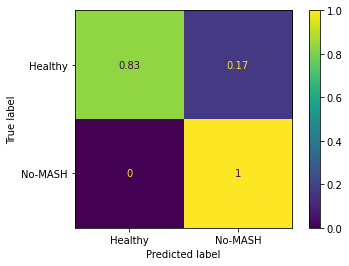

In [11]:
# Confusion_matrix
cmat = confusion_matrix(label_encoder.inverse_transform(y_test), label_encoder.inverse_transform(y_pred),labels=label_encoder.classes_, normalize="true")
disp_cmat = ConfusionMatrixDisplay(confusion_matrix=cmat, display_labels=label_encoder.classes_)
disp_cmat.plot()
plt.show()

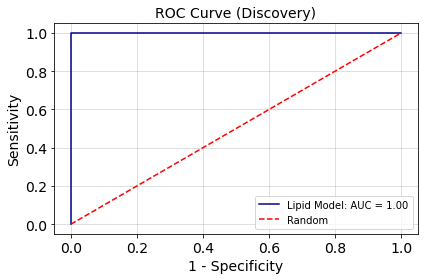

In [12]:
# Calculate ROC and AUC for the models
fpr, tpr, thresholds = roc_curve(y_train_orig, model.predict_proba(X_train_orig.to_numpy())[:, 1])  
auc_score = auc(fpr, tpr)

# Plot ROC curves
plt.figure()
plt.step(fpr, tpr, where='post', label='Lipid Model: AUC = %0.2f' % auc_score, color="darkblue")
plt.plot([0, 1], [0, 1], '--', color='red', label='Random') 

# Add labels, title, legend, and grid
plt.xlabel('1 - Specificity', size=14)
plt.ylabel('Sensitivity', size=14)
plt.title('ROC Curve (Discovery)', size=14)
plt.legend(loc='lower right')
plt.xticks(size=14)
plt.yticks(size=14)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

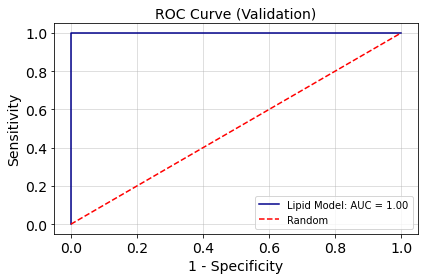

In [13]:
# Calculate ROC and AUC for the models
fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test.to_numpy())[:, 1])  
auc_score = auc(fpr, tpr)

# Plot ROC curves
plt.figure()
plt.step(fpr, tpr, where='post', label='Lipid Model: AUC = %0.2f' % auc_score, color="darkblue")
plt.plot([0, 1], [0, 1], '--', color='red', label='Random') 

# Add labels, title, legend, and grid
plt.xlabel('1 - Specificity', size=14)
plt.ylabel('Sensitivity', size=14)
plt.title('ROC Curve (Validation)', size=14)
plt.legend(loc='lower right')
plt.xticks(size=14)
plt.yticks(size=14)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

## 2. SHAP analysis

In [14]:
shap.initjs()
explainer = shap.KernelExplainer(model.predict_proba, X_train)
shap_values = explainer.shap_values(X_test)

  0%|          | 0/17 [00:00<?, ?it/s]

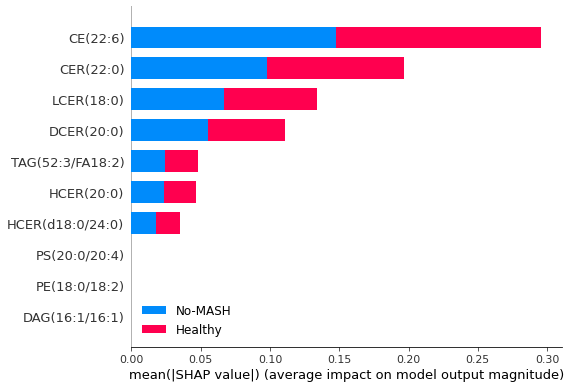

In [15]:
fig, ax = plt.subplots()
shap.summary_plot(shap_values, X_test, max_display=10, plot_type="bar", class_names=label_encoder.inverse_transform(model.classes_), show=False)
plt.show()

1. Shap Summary for Healthy


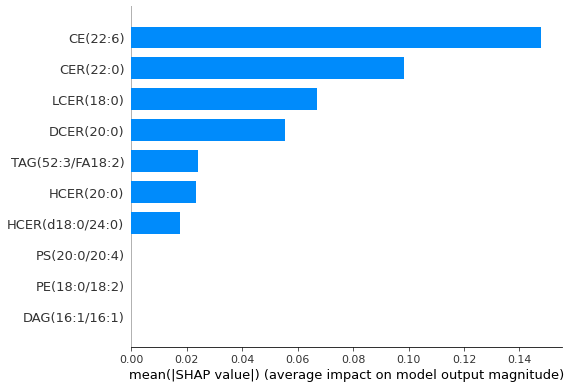

1. Shap Summary for No-MASH


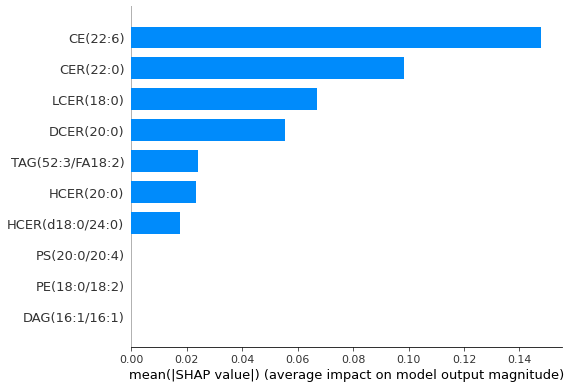

In [16]:
print(f"1. Shap Summary for {label_encoder.inverse_transform(model.classes_)[0]}")
shap.summary_plot(shap_values[0], X_test, max_display=10, plot_type="bar")
print(f"1. Shap Summary for {label_encoder.inverse_transform(model.classes_)[1]}")
shap.summary_plot(shap_values[1], X_test, max_display=10, plot_type="bar")

Shap Summary for Healthy


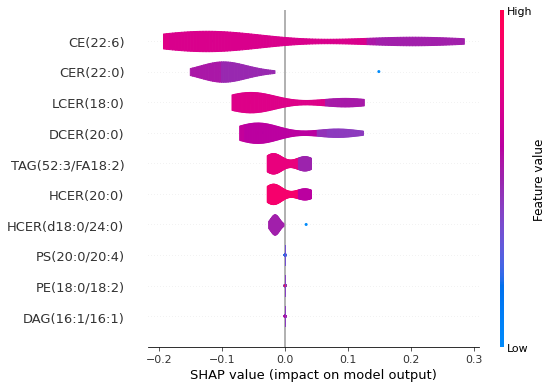

Shap Summary for No-MASH


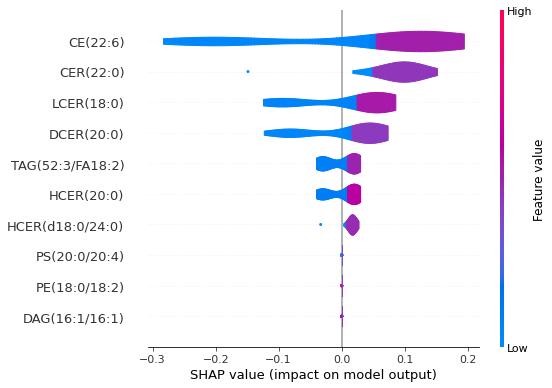

In [17]:
print(f"Shap Summary for {label_encoder.inverse_transform(model.classes_)[0]}")
shap.summary_plot(shap_values[0], X_test, max_display=10, plot_type="violin")
print(f"Shap Summary for {label_encoder.inverse_transform(model.classes_)[1]}")
shap.summary_plot(shap_values[1], X_test, max_display=10, plot_type="violin")

Shap Summary for Healthy


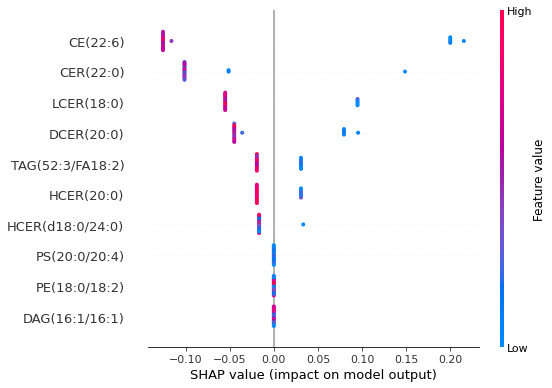

Shap Summary for No-MASH


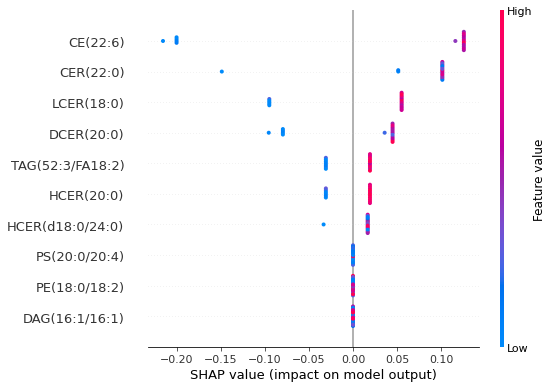

In [18]:
print(f"Shap Summary for {label_encoder.inverse_transform(model.classes_)[0]}")
shap.summary_plot(shap_values[0], X_test, max_display=10, plot_type="dot")
print(f"Shap Summary for {label_encoder.inverse_transform(model.classes_)[1]}")
shap.summary_plot(shap_values[1], X_test, max_display=10, plot_type="dot")

  0%|          | 0/17 [00:00<?, ?it/s]

Beeswarm plot for for Healthy


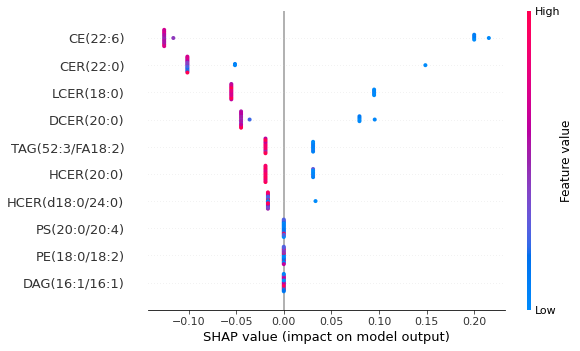

Beeswarm plot for for No-MASH


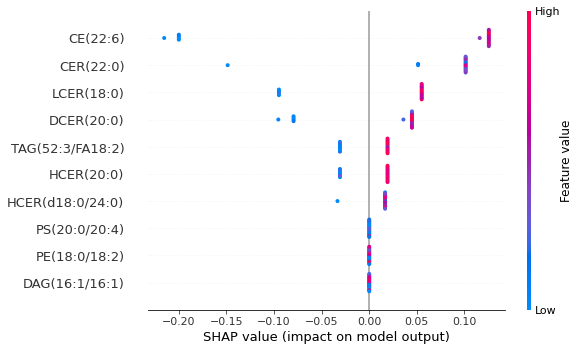

In [19]:
shap_val = explainer(pd.DataFrame(X_test, columns=X_test.columns))
print(f"Beeswarm plot for for {label_encoder.inverse_transform(model.classes_)[0]}")
shap.plots.beeswarm(shap_val[:,:,0])
print(f"Beeswarm plot for for {label_encoder.inverse_transform(model.classes_)[1]}")
shap.plots.beeswarm(shap_val[:,:,1])

Scatter plot for Healthy


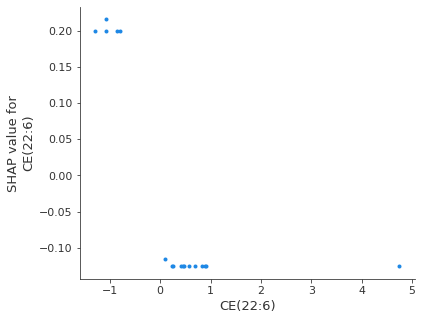

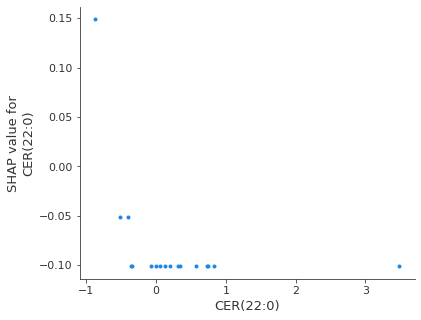

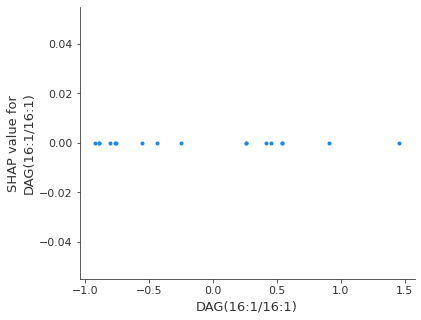

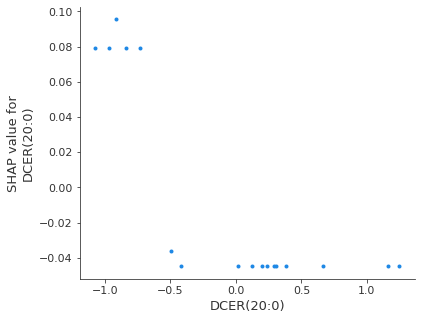

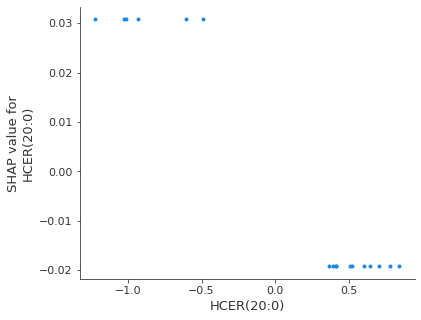

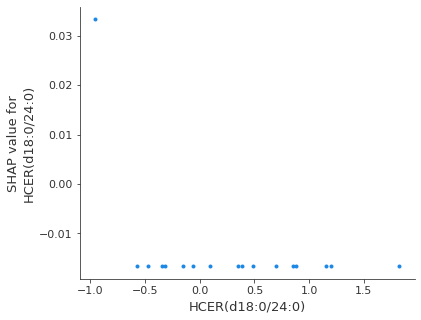

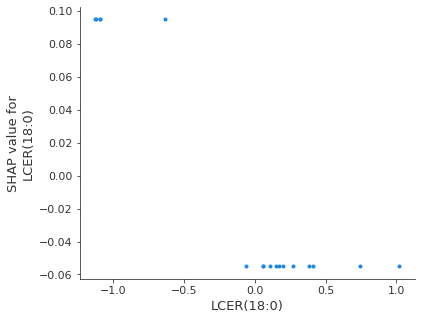

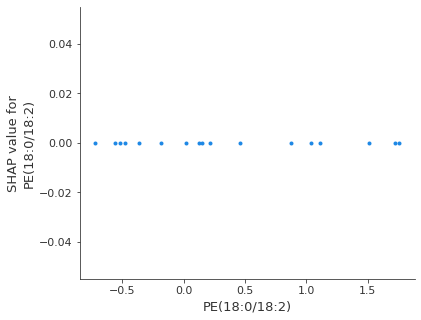

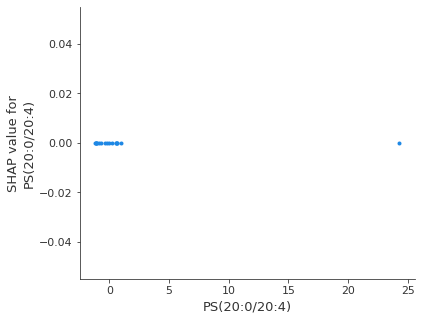

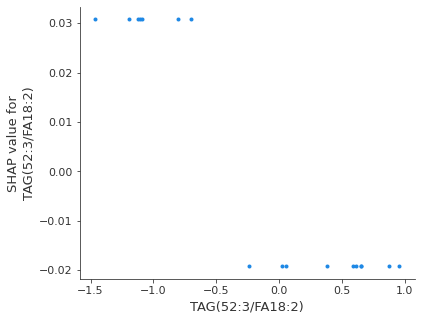

Scatter plot for No-MASH


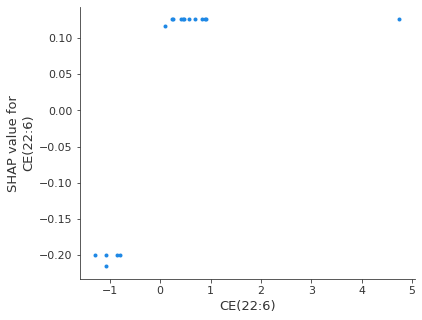

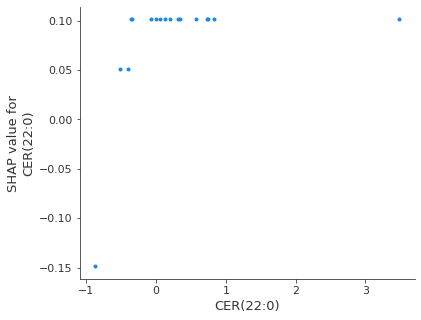

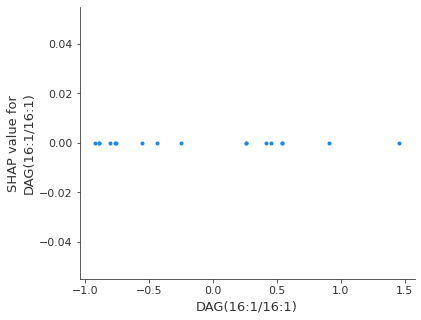

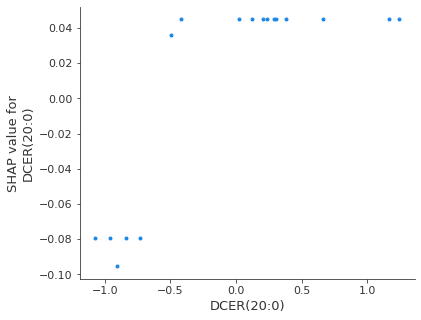

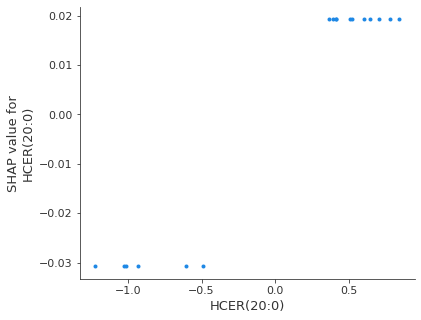

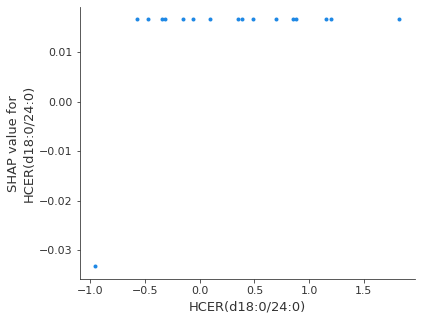

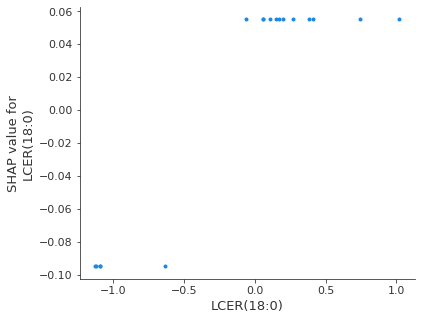

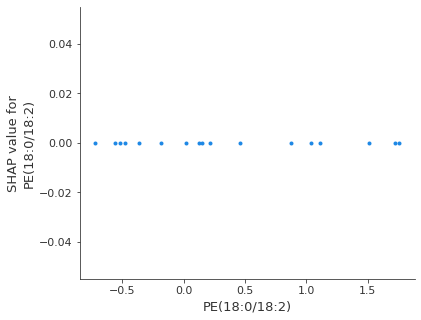

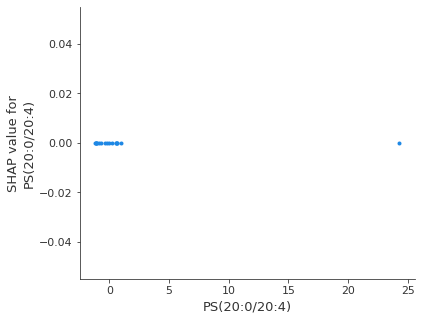

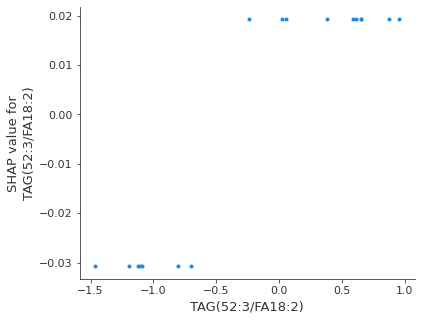

In [20]:
print(f"Scatter plot for {label_encoder.inverse_transform(model.classes_)[0]}")
x = [shap.plots.scatter(shap_val[:, i, 0], hist=False) for i in X_test.columns]

print(f"Scatter plot for {label_encoder.inverse_transform(model.classes_)[1]}")
x = [shap.plots.scatter(shap_val[:, i, 1], hist=False) for i in X_test.columns]

## 3. Risk Modeling

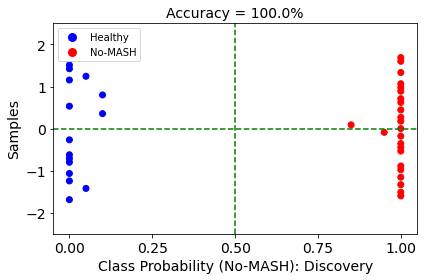

In [21]:
# Predicted Class Probablity | Discovery Data

# Probablity for No-MASH
prob = model.predict_proba(X_train_orig.to_numpy())[:, 1]

# Sample
mean = np.mean(np.arange(len(prob)))
std = np.std(np.arange(len(prob)))
sample = [(i-mean)/std for i in np.arange(len(prob))]

# Plotting
plt.figure()
plt.scatter(prob, sample, c=y_train_orig, cmap='bwr')
plt.axvline(x=0.5, color='green', linestyle='--', label='Threshold (0.5)')
plt.axhline(y=0, color='green', linestyle='--', label='Baseline (y=0)')
plt.yticks(np.arange(-2, 3, 1))
plt.ylim(-2.5, 2.5)
plt.xticks(np.linspace(0, 1, 5))
legend = [Line2D([0], [0], marker='o', color='w', label="Healthy", markerfacecolor='blue', markersize=10),
                   Line2D([0], [0], marker='o', color='w', label="No-MASH",markerfacecolor='red', markersize=10)]
plt.legend(handles=legend, loc='upper left')
plt.title(f'Accuracy = {round(accuracy_score(model.predict(X_train.to_numpy()), y_train)*100, 2)}%',  size=14)
plt.xlabel(f'Class Probability (No-MASH): Discovery',  size=14)
plt.ylabel('Samples',  size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.tight_layout()
plt.show()

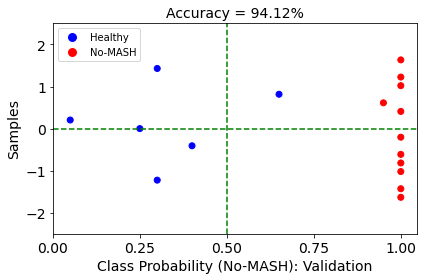

In [22]:
# Predicted Class Probablity | Validation Data

# Probablity for No-MASH
prob = model.predict_proba(X_test.to_numpy())[:, 1]

# Sample
mean = np.mean(np.arange(len(prob)))
std = np.std(np.arange(len(prob)))
sample = [(i-mean)/std for i in np.arange(len(prob))]

# Plotting
plt.figure()
plt.scatter(prob, sample, c=y_test, cmap='bwr')
plt.axvline(x=0.5, color='green', linestyle='--', label='Threshold (0.5)')
plt.axhline(y=0, color='green', linestyle='--', label='Baseline (y=0)')
plt.yticks(np.arange(-2, 3, 1))
plt.ylim(-2.5, 2.5)
plt.xticks(np.linspace(0, 1, 5))
legend = [Line2D([0], [0], marker='o', color='w', label="Healthy", markerfacecolor='blue', markersize=10),
                   Line2D([0], [0], marker='o', color='w', label="No-MASH",markerfacecolor='red', markersize=10)]
plt.legend(handles=legend, loc='upper left')
plt.title(f'Accuracy = {round(accuracy_score(y_pred, y_test)*100, 2)}%',  size=14)
plt.xlabel(f'Class Probability (No-MASH): Validation',  size=14)
plt.ylabel('Samples',  size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.tight_layout()
plt.show()

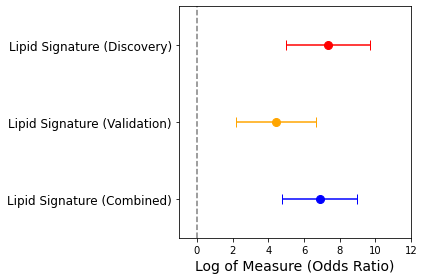

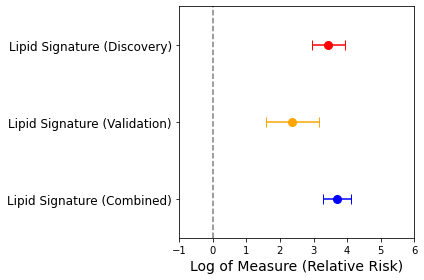

In [23]:
import pandas as pd
from scipy.stats import fisher_exact
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

import numpy as np
from scipy.stats import fisher_exact

import numpy as np
from scipy.stats import fisher_exact
from sklearn.metrics import confusion_matrix

def compute_metrics(data, feature, cutoff, class_col):
    df = data.copy()

    # Binary classification based on cutoff
    df['risk'] = (df[feature] >= cutoff).astype(int)
    df[class_col] = df[class_col].astype(int)

    # Compute confusion matrix
    tn, fp, fn, tp = confusion_matrix(df[class_col], df['risk'], labels=[0, 1]).ravel()
    
    # Adding continuity correction
    a = tp + 0.5
    b = fp + 0.5
    c = fn + 0.5
    d = tn + 0.5

    # Fisher's Exact Test for p-value
    _, p_value = fisher_exact([[a, b], [c, d]])

    # Relative Risk (RR) using Koopman's Asymptotic Score
    rr = (a / (a + b)) / (c / (c + d))

    # Odds Ratio (OR) using Baptista-Pike method
    or_ratio = (a * d) / (b * c)

    # Standard Errors
    se_or = np.sqrt(1 / (a + 1) + 1 / (b + 1) + 1 / (c + 1) + 1 / (d + 1))
    se_rr = np.sqrt((1 - a / (a + b)) / (a + b) + (1 - c / (c + d)) / (c + d))

    # Log-transformed results
    log_or = np.log(or_ratio)
    log_rr = np.log(rr)

    # Confidence Intervals (95%)
    or_lower, or_upper = np.exp(log_or - 1.96 * se_or), np.exp(log_or + 1.96 * se_or)
    rr_lower, rr_upper = np.exp(log_rr - 1.96 * se_rr), np.exp(log_rr + 1.96 * se_rr)
    return log_or, log_rr, (np.log(or_lower), np.log(or_upper)), (np.log(rr_lower), np.log(rr_upper)), p_value

# Analyze features
def analyze_features(data, features, cutoffs, class_col):
    results = []
    for feature, cutoff in zip(features, cutoffs):
        results.append(compute_metrics(data, feature, cutoff, class_col))
    return results

# Inputs
features = ['Prob_No-MASH']
cutoffs = [0.5]
class_col = 'Class'

# Compute probabilities and create datasets
prob = model.predict_proba(X_train_orig.to_numpy())[:, 1]
df_dis = pd.DataFrame({"Class": y_train_orig, "Prob_No-MASH": prob})

prob = model.predict_proba(X_test.to_numpy())[:, 1]
df_val = pd.DataFrame({"Class":y_test, "Prob_No-MASH": prob})

prob = np.array(list(model.predict_proba(X_train_orig.to_numpy())[:, 1])+list(model.predict_proba(X_test.to_numpy())[:, 1]))
df_comb = pd.DataFrame({"Class":np.array(list(y_train_orig)+list(y_test)), "Prob_No-MASH":prob})

# Analyze risks with bootstrapping
risk_train = analyze_features(df_dis, features, cutoffs, class_col)[0]
risk_val = analyze_features(df_val, features, cutoffs, class_col)[0]
risk_comb = analyze_features(df_comb, features, cutoffs, class_col)[0]

# Plotting Forest Plot | Odds Ratio
fig, ax = plt.subplots()

# Discovery
ax.errorbar(
    [risk_train[0]], [2], 
    xerr=[[risk_train[0] - risk_train[2][0]], [risk_train[2][1] - risk_train[0]]], 
    fmt='o', color='red', label='Discovery', capsize=5, markersize=8
)

# Validation
ax.errorbar(
    [risk_val[0]], [1], 
    xerr=[[risk_val[0] - risk_val[2][0]], [risk_val[2][1] - risk_val[0]]], 
    fmt='o', color='orange', label='Validation', capsize=5, markersize=8
)
    
# Combined
ax.errorbar(
    [risk_comb[0]], [0], 
    xerr=[[risk_comb[0] - risk_comb[2][0]], [risk_comb[2][1] - risk_comb[0]]], 
    fmt='o', color='blue', label='Combined', capsize=5, markersize=8
)


# Axes and Titles
ax.set_yticks([2, 1, 0])
ax.set_yticklabels(['Lipid Signature (Discovery)', 'Lipid Signature (Validation)', 'Lipid Signature (Combined)'], size=12)
ax.set_xlabel('Log of Measure (Odds Ratio)',  size=14)
#ax.set_title('Forest Plot for Odds Ratio')
plt.xlim(-1, 12)
plt.ylim(-0.5,2.5)

# Add Reference Line at Log(OR) = 0
ax.axvline(x=0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()


# Plotting Forest Plot | Relative Risk
fig, ax = plt.subplots()

# Discovery
ax.errorbar(
    [risk_train[1]], [2], 
    xerr=[[risk_train[1] - risk_train[3][0]], [risk_train[3][1] - risk_train[1]]], 
    fmt='o', color='red', label='Discovery', capsize=5, markersize=8
)

# Validation
ax.errorbar(
    [risk_val[1]], [1], 
    xerr=[[risk_val[1] - risk_val[3][0]], [risk_val[3][1] - risk_val[1]]], 
    fmt='o', color='orange', label='Validation', capsize=5, markersize=8
)
    
# Combined
ax.errorbar(
    [risk_comb[1]], [0], 
    xerr=[[risk_comb[1] - risk_comb[3][0]], [risk_comb[3][1] - risk_comb[1]]], 
    fmt='o', color='blue', label='Combined', capsize=5, markersize=8
)

# Axes and Titles
ax.set_yticks([2, 1, 0])
ax.set_yticklabels(['Lipid Signature (Discovery)', 'Lipid Signature (Validation)', 'Lipid Signature (Combined)'], size=12)
ax.set_xlabel('Log of Measure (Relative Risk)',  size=14)
plt.xlim(-1, 6)
plt.ylim(-0.5, 2.5)

# Add Reference Line at Log(OR) = 0
ax.axvline(x=0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

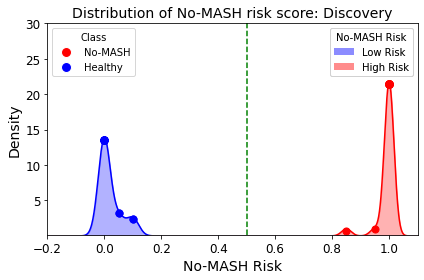

In [24]:
# Risk Scoring | Discovery Only

prob = model.predict_proba(X_train_orig.to_numpy())[:, 1]
# Dataframe with class and No-MASH probablity for each sample
df = pd.DataFrame({"Sample":label_encoder.inverse_transform(y_train_orig), "Prob_No-MASH":prob})

# Function to assign risk category
def assign_risk(prob, threshold = 0.5):
    if prob > threshold:
        return 'High Risk'
    else:
        return 'Low Risk'

# Dataframe with risk category
df['No-MASH_risk'] = df['Prob_No-MASH'].apply(assign_risk)

# KDE plot for risk score
fig, ax = plt.subplots()

# Plotting KDE plot
colors = {'High Risk': 'red', 'Low Risk': 'blue'}
for risk_group in df['No-MASH_risk'].unique():
    subset = df[df['No-MASH_risk'] == risk_group]
    kde = gaussian_kde(subset['Prob_No-MASH'])
    x_vals = np.linspace(-0.2, 1.1, 1000)
    y_vals = kde(x_vals)
    ax.plot(x_vals, y_vals, color=colors[risk_group], label=risk_group)
    ax.fill_between(x_vals, y_vals, alpha=0.3, color=colors[risk_group])

# Plotting scatter plot
for sample_type, color in zip(['No-MASH', 'Healthy'], ['red', 'blue']):
    subset = df[df['Sample'] == sample_type]
    kde = gaussian_kde(subset['Prob_No-MASH'])
    y_vals = kde(subset['Prob_No-MASH'])
    ax.scatter(subset['Prob_No-MASH'], y_vals-0.25, color=color, label=sample_type, s=50)

# Legend1
legend1 = [Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=10, label='No-MASH'),
           Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=10, label='Healthy')]
l1 = ax.legend(handles=legend1, loc='upper left', title='Class', fontsize=10)

# Legend2
legend2 = [Patch(color='blue', label='Low Risk', alpha=0.4, linewidth=0),
           Patch(color='red', label='High Risk', alpha=0.4, linewidth=0)]
l2 = ax.legend(handles=legend2, loc='upper right', title='No-MASH Risk', fontsize=10)

ax.add_artist(l1)
ax.add_artist(l2)
ax.set_ylim(0.15, 30)
ax.set_xlim(-0.2, 1.1)
plt.axvline(x=0.5, color='green', linestyle='--',)
ax.set_title("Distribution of No-MASH risk score: Discovery",  size=14)
ax.set_xlabel("No-MASH Risk",  size=14)
ax.set_ylabel("Density",  size=14)
plt.xticks(size=12)
plt.yticks(size=12)
plt.tight_layout()
plt.show()

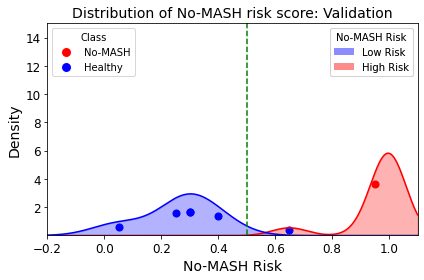

In [25]:
# Risk Scoring | Validation Only

prob = model.predict_proba(X_test.to_numpy())[:, 1]

# Dataframe with class and No-MASH probablity for each sample
df = pd.DataFrame({"Sample":label_encoder.inverse_transform(y_test), "Prob_No-MASH":prob})

# Function to assign risk category
def assign_risk(prob, threshold = 0.5):
    if prob > threshold:
        return 'High Risk'
    else:
        return 'Low Risk'

# Dataframe with risk category
df['No-MASH_risk'] = df['Prob_No-MASH'].apply(assign_risk)

# KDE plot for risk score
fig, ax = plt.subplots()

# Plotting KDE plot
colors = {'High Risk': 'red', 'Low Risk': 'blue'}
for risk_group in df['No-MASH_risk'].unique():
    subset = df[df['No-MASH_risk'] == risk_group]
    kde = gaussian_kde(subset['Prob_No-MASH'], bw_method='scott')
    x_vals = np.linspace(-0.2, 1.1, 1000)
    y_vals = kde(x_vals)
    ax.plot(x_vals, y_vals, color=colors[risk_group], label=risk_group)
    ax.fill_between(x_vals, y_vals, alpha=0.3, color=colors[risk_group])

# Plotting scatter plot
for sample_type, color in zip(['No-MASH', 'Healthy'], ['red', 'blue']):
    subset = df[df['Sample'] == sample_type]
    kde = gaussian_kde(subset['Prob_No-MASH'], bw_method='scott')
    y_vals = kde(subset['Prob_No-MASH'])
    ax.scatter(subset['Prob_No-MASH'], y_vals-0.25, color=color, label=sample_type, s=50)

# Legend1
legend1 = [Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=10, label='No-MASH'),
           Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=10, label='Healthy')]
l1 = ax.legend(handles=legend1, loc='upper left', title='Class', fontsize=10)

# Legend2
legend2 = [Patch(color='blue', label='Low Risk', alpha=0.4, linewidth=0),
           Patch(color='red', label='High Risk', alpha=0.4, linewidth=0)]
l2 = ax.legend(handles=legend2, loc='upper right', title='No-MASH Risk', fontsize=10)

ax.add_artist(l1)
ax.add_artist(l2)
ax.set_ylim(0.05, 15)
ax.set_xlim(-0.2, 1.1)
plt.axvline(x=0.5, color='green', linestyle='--',)
ax.set_title("Distribution of No-MASH risk score: Validation",  size=14)
ax.set_xlabel("No-MASH Risk",  size=14)
ax.set_ylabel("Density",  size=14)
plt.xticks(size=12)
plt.yticks(size=12)
plt.tight_layout()
plt.show()

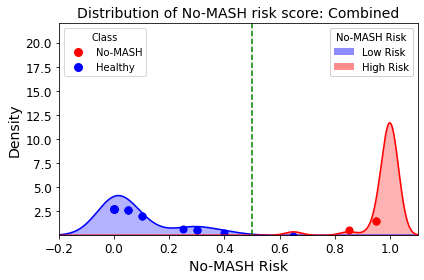

In [26]:
# Risk Scoring | Combined

prob = np.array(list(model.predict_proba(X_train_orig.to_numpy())[:, 1])+list(model.predict_proba(X_test.to_numpy())[:, 1]))

# Dataframe with class and NASH probablity for each sample
df = pd.DataFrame({"Sample":label_encoder.inverse_transform(np.array(list(y_train_orig)+list(y_test))), "Prob_No-MASH":prob})

# Function to assign risk category
def assign_risk(prob, threshold = 0.5):
    if prob > threshold:
        return 'High Risk'
    else:
        return 'Low Risk'

# Dataframe with risk category
df['No-MASH_risk'] = df['Prob_No-MASH'].apply(assign_risk)

# KDE plot for risk score
fig, ax = plt.subplots()

# Plotting KDE plot
colors = {'High Risk': 'red', 'Low Risk': 'blue'}
for risk_group in df['No-MASH_risk'].unique():
    subset = df[df['No-MASH_risk'] == risk_group]
    kde = gaussian_kde(subset['Prob_No-MASH'], bw_method='scott')
    x_vals = np.linspace(-0.2, 1.1, 1000)
    y_vals = kde(x_vals)
    ax.plot(x_vals, y_vals, color=colors[risk_group], label=risk_group)
    ax.fill_between(x_vals, y_vals, alpha=0.3, color=colors[risk_group])

# Plotting scatter plot
for sample_type, color in zip(['No-MASH', 'Healthy'], ['red', 'blue']):
    subset = df[df['Sample'] == sample_type]
    kde = gaussian_kde(subset['Prob_No-MASH'], bw_method='scott')
    y_vals = kde(subset['Prob_No-MASH'])
    ax.scatter(subset['Prob_No-MASH'], y_vals-0.25, color=color, label=sample_type, s=50)

# Legend1
legend1 = [Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=10, label='No-MASH'),
           Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=10, label='Healthy')]
l1 = ax.legend(handles=legend1, loc='upper left', title='Class', fontsize=10)

# Legend2
legend2 = [Patch(color='blue', label='Low Risk', alpha=0.4, linewidth=0),
           Patch(color='red', label='High Risk', alpha=0.4, linewidth=0)]
l2 = ax.legend(handles=legend2, loc='upper right', title='No-MASH Risk', fontsize=10)

ax.add_artist(l1)
ax.add_artist(l2)
ax.set_ylim(0.05, 22)
ax.set_xlim(-0.2, 1.1)
plt.axvline(x=0.5, color='green', linestyle='--',)
ax.set_title("Distribution of No-MASH risk score: Combined",  size=14)
ax.set_xlabel("No-MASH Risk",  size=14)
ax.set_ylabel("Density",  size=14)
plt.xticks(size=12)
plt.yticks(size=12)
plt.tight_layout()
plt.show()